**vbpl.vn đã chuyển sang portal mới (Next.js) nên các trang `.aspx` mà `crawl_data.ipynb` dùng không còn tồn tại.**
Notebook này viết lại phần *Crawl law doc* (cell 29-55 của `crawl_data.ipynb`) theo từng cell tương ứng, dùng 2 nguồn dữ liệu công khai của portal mới:

1. Danh mục văn bản trung ương: `POST https://vbpl.vn/van-ban/trung-uong` (Next.js server action)
2. Chi tiết văn bản: `GET https://vbpl-bientap-gateway.moj.gov.vn/api/qtdc/public/doc/{id}`

Các cell thống kê và vẽ biểu đồ giữ nguyên như bản gốc.

### **Crawl law doc**

#### **Crawl metadata**

In [13]:
import json
import time
from pathlib import Path

import requests

# Notebook có thể chạy từ thư mục Core/ hoặc thư mục gốc của repo
ROOT = Path.cwd() if (Path.cwd() / "Data").exists() else Path.cwd().parent
DOC_DIR = ROOT / "Data" / "doc"
DOC_DIR.mkdir(parents=True, exist_ok=True)

DELAY = 1.0    # số giây tối thiểu giữa 2 request, tránh gây tải cho vbpl.vn
MAX_PAGES = 0  # > 0 để chạy thử với ít trang danh mục
LIMIT = 0      # > 0 để chạy thử với ít văn bản

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0.0.0 Safari/537.36"
}
session = requests.Session()
session.headers.update(headers)
last_request = 0.0


def request(method, url, max_retries=5, **kwargs):
    """Gửi request tuần tự, giãn cách tối thiểu DELAY giây, retry với backoff khi bị giới hạn hoặc lỗi server."""
    global last_request
    for attempt in range(1, max_retries + 1):
        wait = DELAY - (time.monotonic() - last_request)
        if wait > 0:
            time.sleep(wait)
        last_request = time.monotonic()
        try:
            response = session.request(method, url, timeout=60, **kwargs)
            # Không retry 500: API trả 500 cố định cho một số văn bản bị lỗi dữ liệu phía server
            if response.status_code not in (429, 502, 503, 504):
                return response
            print(f"HTTP {response.status_code} từ {url} (lần {attempt}/{max_retries})")
        except requests.RequestException as e:
            print(f"Lỗi kết nối {url} (lần {attempt}/{max_retries}): {e}")
        time.sleep(min(2 ** attempt * DELAY, 120))
    raise RuntimeError(f"Không truy cập được {url}")


def format_date(value):
    """ISO datetime của API (2012-07-30T00:00:00) -> DD/MM/YYYY như dữ liệu gốc."""
    return "/".join(value[:10].split("-")[::-1]) if value else ""

In [ ]:
import requests
import json
import re

# ID của Next.js server action trả về danh mục văn bản, đổi mỗi khi vbpl.vn deploy lại: khi không đọc được
# danh mục, mở https://vbpl.vn/van-ban/trung-uong, chuyển trang trong danh sách rồi lấy header "Next-Action"
# của request POST trong DevTools (tab Network).
CATALOG_ACTION_ID = "c529d164f28418e5898a834422629e64c6816af1"


def get_doc_list(page=1):
    url = "https://vbpl.vn/van-ban/trung-uong"

    payload = [{
        "pageNumber": page,
        "pageSize": 100,
        "keyword": "Doanh nghiệp",
    }]

    response = request("POST", url,
                       data=json.dumps(payload, ensure_ascii=False).encode("utf-8"),
                       headers={
                           "Accept": "text/x-component",
                           "Content-Type": "text/plain;charset=UTF-8",
                           "Next-Action": CATALOG_ACTION_ID,
                           "Origin": "https://vbpl.vn",
                           "Referer": url,
                       })
    # Response là React Server Components, không khai báo charset nên phải tự decode UTF-8
    text = response.content.decode("utf-8")

    catalog = None
    for marker in re.finditer(r"[0-9a-f]+:(?=\{)", text):
        try:
            data, _ = json.JSONDecoder().raw_decode(text, marker.end())
        except json.JSONDecodeError:
            continue
        if isinstance(data, dict) and isinstance(data.get("items"), list):
            catalog = data
            break
    if catalog is None:
        raise RuntimeError("Không đọc được danh mục, có thể CATALOG_ACTION_ID đã đổi")

    info_list = []

    for info in catalog["items"]:
        law_info = {}

        law_info['title'] = info['title'].strip()
        law_info['link'] = info['document_url']

        law_info['description'] = (info.get('docAbs') or '').strip()
        law_info['doc_num'] = info.get('docNum')
        law_info['doc_type'] = (info.get('docType') or {}).get('name')

        law_info['date_issued'] = format_date(info.get('issueDate'))
        law_info['effective_date'] = format_date(info.get('effFrom'))

        status = (info.get('effStatus') or {}).get('name')
        law_info['status'] = status if status else "Còn hiệu lực"

        info_list.append(law_info)

    return info_list

# get_doc_list(1)

In [ ]:
law_info_list = []
page_passed = set()

In [ ]:
for page in range(1, 1000):
    if MAX_PAGES and page > MAX_PAGES:
        break
    if page not in page_passed:
        try:
            info_list = get_doc_list(page)
            if len(info_list) == 0:
                break

            law_info_list.extend(info_list)
            page_passed.add(page)
        except Exception as e:
            print(page, e)

len(law_info_list)

In [ ]:
for law_info in law_info_list:
    law_info['id'] = law_info['link'].split('/')[-1]

# Portal mới tìm từ khóa trong toàn văn, nên lọc lại theo tên văn bản (bản gốc tìm theo "Title1,Title")
# và chỉ giữ các loại văn bản quy phạm pháp luật như bản gốc (bỏ công văn, văn bản hợp nhất, ...).
# Thứ tự danh mục có thể thay đổi trong lúc crawl nên cần loại trùng theo id.
types = 'Hiến pháp,Bộ luật,Luật,Pháp lệnh,Lệnh,Nghị quyết,Nghị quyết liên tịch,Nghị định,Quyết định,Thông tư,Thông tư liên tịch,Chỉ thị'
law_info_list = list({
    law_info['id']: law_info
    for law_info in law_info_list
    if "doanh nghiệp" in law_info['title'].lower() and law_info['doc_type'] in types.split(',')
}.values())

len(law_info_list)

In [ ]:
import json

with open(DOC_DIR / "law_info_list.json", "w", encoding="utf-8") as f:
    json.dump(law_info_list, f, indent=4, ensure_ascii=False)

#### **Crawl doc**

In [14]:
import json

with open(DOC_DIR / 'law_info_list.json', 'r', encoding='utf-8') as file:
    law_info_list = json.load(file)

In [15]:
import requests

def crawl_law(info):
    url = f'https://vbpl-bientap-gateway.moj.gov.vn/api/qtdc/public/doc/{info["id"]}'

    response = request("GET", url, headers={"Accept": "application/json", "Referer": "https://vbpl.vn/"})
    if response.status_code != 200:
        raise RuntimeError(f"Không thể truy cập trang web (HTTP {response.status_code})")

    document = response.json()['data']

    # Cập nhật thông tin chi tiết chỉ có ở trang văn bản
    info['expiry_date'] = format_date(document.get('effTo'))
    info['agency'] = document.get('agencyName')
    status = (document.get('effStatus') or {}).get('name')
    if status:
        info['status'] = status

    law = {'metadata': info}
    law['html_data'] = (document.get('documentContent') or {}).get('content') or ''

    return law

In [16]:
law_data = []
law_crawled = set()

# Checkpoint: crawl chi tiết mất vài giờ, mỗi văn bản được ghi ngay ra file để chạy lại không mất dữ liệu
checkpoint_path = DOC_DIR / "law_html_checkpoint.jsonl"
if checkpoint_path.exists():
    with open(checkpoint_path, 'r', encoding='utf-8') as f:
        for line in f:
            law = json.loads(line)
            law_data.append(law)
            law_crawled.add(law['metadata']['id'])

len(law_data)

1172

In [17]:
todo = [info for info in law_info_list if info['id'] not in law_crawled]
if LIMIT:
    todo = todo[:LIMIT]

law_failed = []
with open(checkpoint_path, 'a', encoding='utf-8') as checkpoint:
    for info in todo:
        try:
            law = crawl_law(info=info)
            law_data.append(law)
            law_crawled.add(info['id'])
            checkpoint.write(json.dumps(law, ensure_ascii=False) + "\n")
            checkpoint.flush()
        except Exception as e:
            law_failed.append(info['id'])
            print(info['id'], e)

# Chạy lại cell này để thử lại các văn bản lỗi
print(f"Lỗi {len(law_failed)} văn bản: {law_failed}")
len(law_data)

22299 Không thể truy cập trang web (HTTP 500)
22214 Không thể truy cập trang web (HTTP 500)
22542 Không thể truy cập trang web (HTTP 500)
23169 Không thể truy cập trang web (HTTP 500)
22082 Không thể truy cập trang web (HTTP 500)
21342 Không thể truy cập trang web (HTTP 500)
23570 Không thể truy cập trang web (HTTP 500)
24303 Không thể truy cập trang web (HTTP 500)
Lỗi kết nối https://vbpl-bientap-gateway.moj.gov.vn/api/qtdc/public/doc/8288 (lần 1/5): ('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))
22213 Không thể truy cập trang web (HTTP 500)
22765 Không thể truy cập trang web (HTTP 500)
21627 Không thể truy cập trang web (HTTP 500)
21631 Không thể truy cập trang web (HTTP 500)
21895 Không thể truy cập trang web (HTTP 500)
Lỗi 13 văn bản: ['22299', '22214', '22542', '23169', '22082', '21342', '23570', '24303', '22213', '22765', '21627', '21631', '21895']


3280

In [18]:
import json
import unicodedata

with open(DOC_DIR / "law_html.json", "w", encoding="utf-8") as f:
    law_data_normalized = []
    for data in law_data:
        data_json = data.copy()
        data_json['html_data'] = unicodedata.normalize("NFKC", str(data_json['html_data']))
        law_data_normalized.append(data_json)

    json.dump(law_data_normalized, f, indent=4, ensure_ascii=False)

#### **Preprocessing**

In [19]:
import json

with open(DOC_DIR / 'law_html.json', 'r', encoding='utf-8') as file:
    law_raw = json.load(file)

In [20]:
types = 'Hiến pháp,Bộ luật,Luật,Pháp lệnh,Lệnh,Nghị quyết,Nghị quyết liên tịch,Nghị định,Quyết định,Thông tư,Thông tư liên tịch,Chỉ thị'
document_types = sorted(types.split(','), key=len, reverse=True)
document_types

['Nghị quyết liên tịch',
 'Thông tư liên tịch',
 'Nghị quyết',
 'Quyết định',
 'Hiến pháp',
 'Pháp lệnh',
 'Nghị định',
 'Thông tư',
 'Bộ luật',
 'Chỉ thị',
 'Luật',
 'Lệnh']

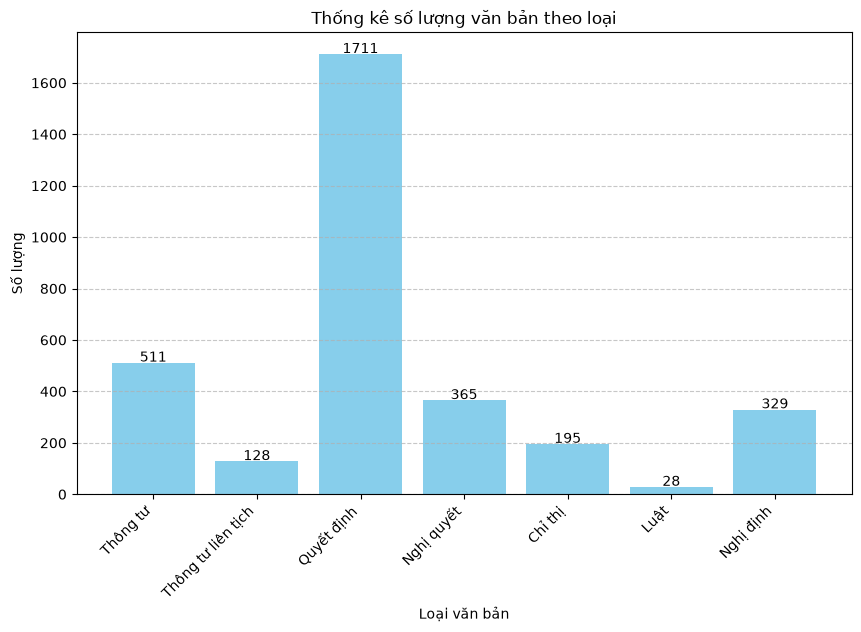

In [21]:
import matplotlib.pyplot as plt
from collections import Counter

def show_num_doc(law_raw):
    # Bộ đếm số lượng từng loại văn bản
    counter = Counter()

    # Duyệt qua từng mục trong danh sách JSON
    for item in law_raw:
        title = item["metadata"]["title"]
        for doc_type in document_types:
            if doc_type in title:
                counter[doc_type] += 1
                break  # Đếm mỗi văn bản theo loại đầu tiên khớp

    # Vẽ biểu đồ
    plt.figure(figsize=(10, 6))
    plt.bar(counter.keys(), counter.values(), color="skyblue")
    plt.xlabel("Loại văn bản")
    plt.ylabel("Số lượng")
    plt.title("Thống kê số lượng văn bản theo loại")
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.7)

    # Hiển thị số lượng trên cột
    for i, v in enumerate(counter.values()):
        plt.text(i, v + 5, str(v), ha="center", fontsize=10)

    plt.show()

show_num_doc(law_raw)

In [22]:
law_raw = [item for item in law_raw if "Lệnh" not in item["metadata"]["title"] and "Chỉ thị" not in item["metadata"]["title"]]

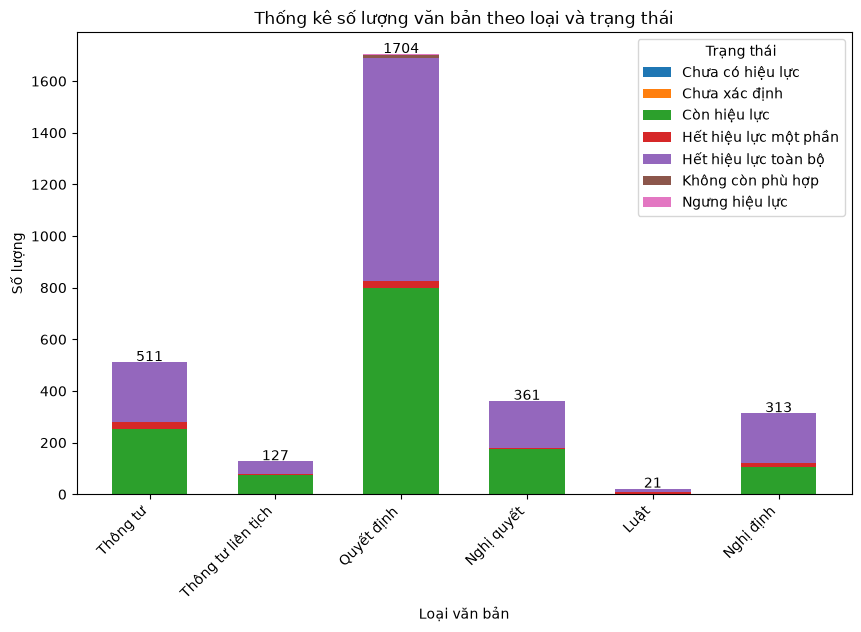

In [23]:

import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict, Counter

# Bộ đếm số lượng từng loại văn bản theo status
doc_status_counts = defaultdict(Counter)

# Duyệt qua danh sách dữ liệu
for item in law_raw:
    title = item["metadata"]["title"]
    status = item["metadata"]["status"]

    for doc_type in document_types:
        if doc_type in title:
            doc_status_counts[doc_type][status] += 1
            break  # Chỉ tính theo loại đầu tiên khớp

# Danh sách các trạng thái hiệu lực
all_statuses = set()
for counts in doc_status_counts.values():
    all_statuses.update(counts.keys())
all_statuses = sorted(all_statuses)  # Đảm bảo thứ tự trạng thái

# Chuẩn bị dữ liệu vẽ biểu đồ
labels = list(doc_status_counts.keys())  # Các loại văn bản
status_data = {status: [doc_status_counts[doc].get(status, 0) for doc in labels] for status in all_statuses}

# Vẽ biểu đồ cột xếp chồng (stacked bar chart)
x = np.arange(len(labels))  # Tọa độ x
width = 0.6  # Độ rộng cột

fig, ax = plt.subplots(figsize=(10, 6))

bottom = np.zeros(len(labels))  # Vị trí bắt đầu cho cột xếp chồng

for status in all_statuses:
    values = status_data[status]
    ax.bar(x, values, width, label=status, bottom=bottom)
    bottom += np.array(values)  # Cộng dồn cho phần tiếp theo

# Gán nhãn
ax.set_xlabel("Loại văn bản")
ax.set_ylabel("Số lượng")
ax.set_title("Thống kê số lượng văn bản theo loại và trạng thái")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.legend(title="Trạng thái")

# Hiển thị số lượng trên cột
for i in range(len(labels)):
    total = sum(status_data[status][i] for status in all_statuses)
    ax.text(i, total + 5, str(total), ha="center", fontsize=10, color="black")


plt.show()

In [24]:
from bs4 import BeautifulSoup

In [25]:
# Bản gốc in law_raw[300]; dùng min() để notebook vẫn chạy được khi chạy thử với ít văn bản
sample = min(300, len(law_raw) - 1)
print(BeautifulSoup(law_raw[sample]['html_data'], "html.parser").text.strip())

Document Content



NGHỊ ĐỊNH
Về công bố thông tin của doanh nghiệp nhà nước
___________________
 
Căn cứ Luật Tổ chức Chính phủ ngày 25 tháng 12 năm 2001;
Căn cứ Luật Kế toán ngày 17 tháng 6 năm 2003;
Căn cứ Luật Thống kê ngày 17 tháng 6 năm 2003;
Căn cứ Luật Doanh nghiệp ngày 26 tháng 11 năm 2014;
Căn cứ Luật Đầu tư ngày 26 tháng 11 năm 2014;
Căn cứ Luật Quản lý, sử dụng vốn nhà nước đầu tư vào sản xuất, kinh doanh tại doanh nghiệp ngày 26 tháng 11 năm 2014;
Theo đề nghị của Bộ trưởng Bộ Kế hoạch và Đầu tư,
Chính phủ ban hành Nghị định về công bố thông tin của doanh nghiệp nhà nước.
Chương I
NHỮNG QUY ĐỊNH CHUNG
Điều 1. Phạm vi điều chỉnh
Nghị định này quy định về nội dung, trình tự, thủ tục, trách nhiệm công bố thông tin của doanh nghiệp nhà nước.
Điều 2. Đối tượng áp dụng
1. Cơ quan đại diện chủ sở hữu nhà nước.
2. Doanh nghiệp nhà nước.
3. Cơ quan, tổ chức, cá nhân có liên quan đến việc công bố thông tin của doanh nghiệp nhà nước.
4. Các doanh nghiệp nhà nước trực tiếp phục vụ quố

In [26]:
len(law_raw[sample]['html_data'].split())

6276

In [27]:
import re

law_corpus = law_raw.copy()

for law in law_corpus:
    soup = BeautifulSoup(law['html_data'], "html.parser")
    # Portal mới trả về cả trang HTML (có <style> CSS), portal cũ chỉ có table.detailcontent
    for tag in soup(['style', 'script', 'head', 'title']):
        tag.decompose()
    text = soup.text.strip()
    text = re.sub(r'\n+\t*', ' \n ', text)
    law['data'] = re.sub(r'[ ]+', ' ', text)

In [28]:
law_corpus = [law for law in law_corpus if len(law['data']) > 10]

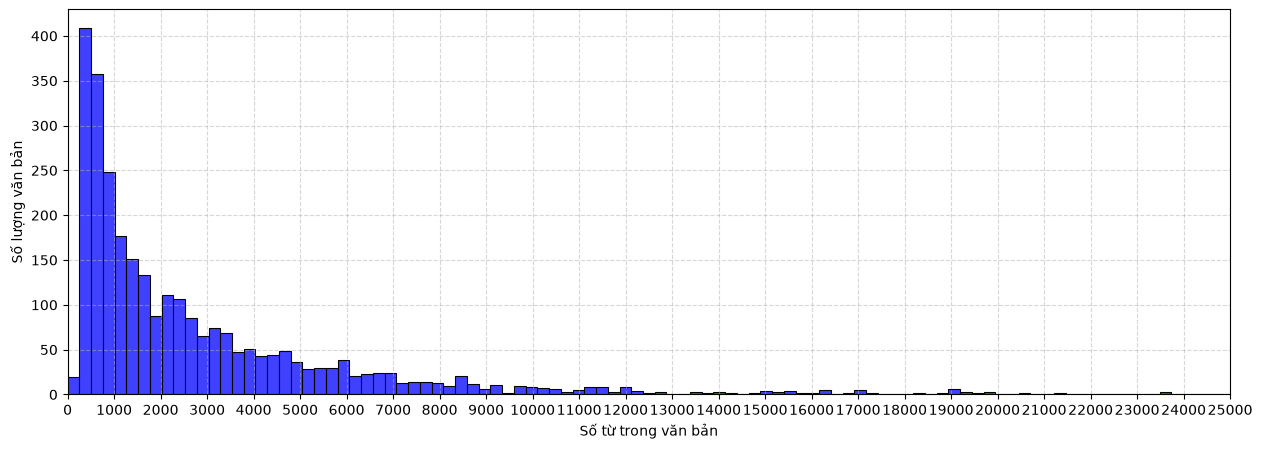

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns


doc_lengths = []
for law in law_corpus:
    doc_lengths.append(len(law['data'].split(" ")))


bins = np.linspace(0, 25000, num=100)  

# Vẽ histogram
plt.figure(figsize=(15, 5))
sns.histplot(doc_lengths, bins=bins, kde=False, color="blue")

# Cấu hình biểu đồ
plt.xlim(0, 25000)
plt.xticks(np.arange(0, 25001, step=1000))
plt.xlabel("Số từ trong văn bản")
plt.ylabel("Số lượng văn bản")
plt.grid(True, linestyle="--", alpha=0.5)

# Hiển thị biểu đồ
plt.show()

In [30]:
max(doc_lengths)

246963

In [31]:
with open(DOC_DIR / "law_corpus.json", "w", encoding="utf-8") as f:
    json.dump(law_corpus, f, indent=4, ensure_ascii=False)